In [1]:
# Notebook used to display the results from raytrace_3d_curve.py

In [2]:
# %matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

import particle_tracker as pt
import ray_transfer_matrix as rtm

from PIL import Image, ImageChops
import yt.units

In [27]:
# Get data

ray_trace_dir = '/home/timoney/scratch/timoney/MagShockZ/LIONZ_MagShockZ/outputs/traces/synthetic_trace/curve_sff_5'
# output_dir = '/home/timoney/scratch/timoney/MagShockZ/images/fp_test'

metadata = {}
raytrace_metadata = ray_trace_dir + '/metadata.txt'
with open(raytrace_metadata, 'r') as f:
    metadata_lines = f.readlines()
    for line in metadata_lines:
        key, value = line.strip().split(': ')
        metadata[key] = value

print(metadata)

{'num_photons': '1000000', 'beam_size': '0.012', 'divergence': '0', 'num_processors': '36', 'timestamp': '1791558481.5182946'}


In [28]:
rf = np.load(f"{ray_trace_dir}/ray_output.npy")
beam_size = float(metadata["beam_size"])
photons = int(metadata["num_photons"])

det_size = 2*float(metadata['beam_size'])*10**3 # 10^3 to convert into mm
lens_rad=25
length=400
fp=0

sh = rtm.Shadowgraphy(r0=rf, focal_plane=fp, L=length, R=lens_rad, Lx=det_size, Ly=det_size)
sh.solve()
#lionz = rtm.LIONZ_approx()

lsc = rtm.Schlieren_LF(r0=rf, focal_plane=fp, L=length, R=lens_rad, Lx=det_size, Ly=det_size)
lsc.solve()
lsc.histogram(bin_scale=1)
sh.histogram(bin_scale=1)
# try plotting histogram

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(2574, 3448))

Text(0.5, 0, 'X [mm]')

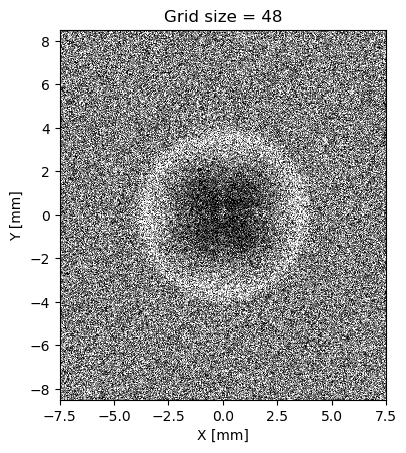

In [29]:
# define LIONZ optical system
output_dir = '/home/timoney/scratch/timoney/MagShockZ/images/ch'
# focal_plane = (ds.r[('flash','z')][-1]-ds.r[('flash','z')][0])/2*10 # midplane of simulation (multiply by 10 to convert to mm)
# print(ds.r[('flash','z')][-1])
# print(ds.r[('flash','z')][0])
# focal_plane = focal_plane.v #take out yt unit
# focal_plane = ((z_coords.max() - z_coords.min()) / 2) * 1000
# print("focal plane [mm]:", focal_plane)
focal_plane = 8

offset_mm = 0 # offset for focusing
Lens_FL = 400
total_dist = 450+3600 # distance from target to first image plane default = 450 + 3600
if Lens_FL == 400:
    d1= 450
elif Lens_FL == 500:
    d1 = 584.3

d2 =total_dist-d1
Lens_Rad = .5*75 # radius of lens
Lens_Rad = 50000000000000000

sh = rtm.LIONZ_approx(r0 = rf, Lx = 15, Ly = 17, focal_plane = focal_plane+offset_mm, L=Lens_FL, R=Lens_Rad) # must center grid
sh.solve(d1=d1,d2=d2)

sh.histogram(bin_scale = 7)
# plot
fig, axs = plt.subplots()
cm='gray'
#clim=[0,15]

vmin=np.percentile(sh.H, 5)
vmax=np.percentile(sh.H,90) #default is 90
# print(vmax)

clim=(0,vmax*1) # trial and error
sh.plot(axs, cmap=cm, clim=clim)

plt.title('Grid size = 48')

plt.ylabel('Y [mm]')
plt.xlabel('X [mm]')